# Weekly red-tide forecast models for the Sarasota coast

One section per model. Each model predicts the *K. brevis* class (no bloom, at risk, bloom) in the Sarasota target box 1, 2 and 4 weeks ahead, from the weekly table built in `00_master_eda_and_merge.ipynb`.

| § | Model | Type |
|---|---|---|
| 2 | Persistence | baseline: next week = last observed week |
| 3 | Seasonal climatology | baseline: what is usual for this time of year |
| 4 | Logistic regression | linear, interpretable |
| 5 | Random forest | tree ensemble |
| 6 | XGBoost | gradient-boosted trees |
| 7 | Hybrid LR, Hybrid XGB | **a hybrid of two models:** persistence plus a learned model (logistic regression or XGBoost) that can raise a warning when a quiet week may turn |
| 8 | Comparison | all models side by side |

**What "hybrid" means here.** Each hybrid combines two models. Every week:
* if the last observed week was **at risk or bloom**, it keeps that class (persistence: blooms usually continue);
* if it was **no bloom**, it asks the learned model how likely a change to at risk or bloom is, and **raises a warning only if that probability is above a threshold** learned from the training years.

So persistence handles the steady weeks, where it is very accurate, and the learned model only steps in to warn that quiet water may be about to turn, which persistence can never do. *Hybrid LR* uses logistic regression as the learned model; *Hybrid XGB* uses XGBoost. Details in §7.

This notebook reads saved results; the training code is in one folder per model (`persistence/`, `seasonal_climatology/`, `logistic_regression/`, `random_forest/`, `xgboost/`, `hybrid_escalation/`).

## 0. Setup

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from common.config import MODELS_ROOT
import common.evaluation   # switches matplotlib to a non-display backend on import,
%matplotlib inline
# ...so inline plotting is switched back on here.
R = MODELS_ROOT / "results"
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

files = sorted(R.glob("h*w/*/metrics.csv"))
results = (pd.concat([pd.read_csv(f).assign(horizon=f.parent.parent.name) for f in files], ignore_index=True)
           if files else pd.DataFrame(columns=["model", "feature_set", "scheme", "horizon"]))
results = results[results["scheme"] == "forward"].reset_index(drop=True)

METRICS = {"accuracy": "accuracy", "macro_f1": "macro-F1", "recall_at_risk": "at-risk recall", "recall_bloom": "bloom recall",
           "warning_recall": "warning recall", "warning_precision": "warning precision",
           "onsets_caught_any_warning": "onsets flagged (of 11)", "escalation_recall": "escalations caught",
           "pr_auc_bloom": "bloom PR-AUC"}


def model_table(model):
    """Forward-chaining results of one model, one row per horizon and feature set.

    Args:
        model (str): Model folder name in results/, e.g. "logistic_regression".

    Returns:
        pandas.DataFrame: Key metrics, rounded, sorted by horizon then macro-F1.
    """
    d = results[results["model"] == model].sort_values(["horizon", "macro_f1"], ascending=[True, False])
    d = d.set_index(["horizon", "feature_set"])[list(METRICS)].rename(columns=METRICS)
    return d.round(2)


def show(model, feature_set, horizon="h1w", kind="timeline"):
    """Display a saved timeline or confusion-matrix figure.

    Args:
        model (str): Model folder name in results/.
        feature_set (str): Feature set, e.g. "kb_only".
        horizon (str): "h1w", "h2w" or "h4w".
        kind (str): "timeline" or "confusion".

    Returns:
        None
    """
    display(Image(R / horizon / model / f"{kind}__{feature_set}__forward.png"))

def by_year(model, feature_set, horizon="h1w"):
    """Accuracy and macro-F1 of one model for each forward-chaining test year.

    Args:
        model (str): Model folder name in results/.
        feature_set (str): Feature set, e.g. "kb_only".
        horizon (str): "h1w", "h2w" or "h4w".

    Returns:
        pandas.DataFrame: One row per test bloom year (Aug-Jul, named by the year it ends).
    """
    from sklearn.metrics import accuracy_score, f1_score
    p = pd.read_csv(R / horizon / model / f"predictions__{feature_set}__forward.csv", index_col=0)
    rows = {y: {"test weeks": len(g), "accuracy": accuracy_score(g.y_true, g.y_pred),
                "macro-F1": f1_score(g.y_true, g.y_pred, labels=[0, 1, 2], average="macro", zero_division=0)}
            for y, g in p.groupby("bloom_year")}
    out = pd.DataFrame(rows).T
    out["test weeks"] = out["test weeks"].astype(int)
    out.index = [f"Aug {y - 1} - Jul {y}" for y in out.index]
    return out.round(2).T

def timeline(model, feature_set, horizon="h1w"):
    """Show what kind of forecast each test week got, over time and per test year.

    Each test week is classed as: correct; missed warning (at risk or bloom happened,
    no bloom forecast); false alarm (warning forecast, no bloom happened); or wrong
    level (at risk and bloom mixed up). Weeks are drawn at the week being forecast.

    Args:
        model (str): Model folder name in results/.
        feature_set (str): Feature set, e.g. "kb_only".
        horizon (str): "h1w", "h2w" or "h4w".

    Returns:
        None
    """
    from matplotlib.patches import Patch
    h = int(horizon[1])
    p = pd.read_csv(R / horizon / model / f"predictions__{feature_set}__forward.csv", index_col=0, parse_dates=True)
    week = p.index + pd.Timedelta(weeks=h)                      # the week being forecast
    t, f = p["y_true"], p["y_pred"]
    outcome = pd.Series("correct", index=p.index)
    outcome[(t >= 1) & (f == 0)] = "missed warning"
    outcome[(t == 0) & (f >= 1)] = "false alarm"
    outcome[(t >= 1) & (f >= 1) & (t != f)] = "wrong level"
    OUT = {"correct": "0.85", "missed warning": "tab:red", "false alarm": "tab:orange", "wrong level": "tab:purple"}
    CLS = {0: "tab:green", 1: "gold", 2: "darkred"}

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 2.8), gridspec_kw={"width_ratios": [3.2, 1]})
    ax.bar(week, 0.35, width=7, bottom=1.05, color=t.map(CLS), align="edge")           # what happened
    ax.bar(week, 0.8, width=7, bottom=0, color=outcome.map(OUT), align="edge")         # how the forecast did
    ax.set_yticks([1.22, 0.4], ["what happened", "forecast result"]); ax.set_ylim(-0.1, 1.5)
    ax.set_title(f"{model} | {feature_set} | {h} week(s) ahead: correct in {(outcome == 'correct').mean():.0%} of {len(p)} test weeks")
    ax.legend(handles=[Patch(color=CLS[0], label="no bloom"), Patch(color=CLS[1], label="at risk"), Patch(color=CLS[2], label="bloom")]
                      + [Patch(color=c, label=l) for l, c in OUT.items()],
              frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=7, fontsize=8)
    per_year = pd.crosstab(p["bloom_year"], outcome).reindex(columns=list(OUT), fill_value=0)
    per_year.index = [f"{y - 1}-{str(y)[2:]}" for y in per_year.index]
    per_year.plot(kind="bar", stacked=True, ax=ax2, color=list(OUT.values()), width=0.8, legend=False)
    ax2.set_title("weeks per test year", fontsize=10); ax2.tick_params(axis="x", labelsize=7, rotation=60)
    plt.tight_layout(); plt.show()

print(f"{results['model'].nunique()} models x {results['horizon'].nunique()} horizons, {len(results)} result rows")

3 models x 3 horizons, 18 result rows


---
## 1. How the models are evaluated

**Label.** The class of the highest *K. brevis* count in the Sarasota target box that week: no bloom (< 10⁴ cells/L), at risk (10⁴–10⁵), bloom (≥ 10⁵). Each model forecasts it **1, 2 or 4 weeks ahead** using only data up to the current week.

**Feature sets** (built in `00_master_eda_and_merge.ipynb` §10):

| Set | Contents | Question it answers |
|---|---|---|
| `kb_only` | season + 21 bloom-history features | How far does bloom history alone go? |
| `env_only` | season + chlorophyll + water quality + water temperature + air and rain | Can the environment predict blooms without current cell counts? |
| `long` | `kb_only` + `env_only` (sources covering 2010 onward) | Does the environment add to bloom history? |
| `full` | `long` + wind + Mote temperature (short records) | Do the short-record sources help? |

**Forward-chaining by bloom year.** Weeks are grouped into August–July "bloom years", so one red-tide season never sits in both training and test data. For each test year from 2016 onward, a model is trained on all earlier years only and tested on that year. This is time-series cross-validation: the model never sees the future it is tested on [1]. Because the label is the class *h* weeks later, the last *h* training weeks before a test year would have labels from inside that year; those weeks are removed from training (purged), so no test-year information reaches the model. All results in this notebook use it (448 test weeks at 1 week ahead).

**Metrics.** For one class (e.g. bloom), each test week is a true positive (TP: predicted bloom and was bloom), false positive (FP: predicted bloom but wasn't), false negative (FN: was bloom but predicted something else) or true negative.

* **Precision** = TP / (TP + FP): of the weeks predicted as bloom, the share that were bloom.
* **Recall** = TP / (TP + FN): of the real bloom weeks, the share predicted as bloom.
* **F1** = 2 × precision × recall / (precision + recall): one number that is high only if both are high.
* **Accuracy** = correct weeks / all weeks. With 72 % of weeks no bloom, a model that always says "no bloom" already scores 0.72, so accuracy alone flatters weak models.
* **Macro-F1** = the average of the F1 of the three classes. Each class counts equally, so the rare at-risk and bloom weeks matter as much as no-bloom weeks. This is the main score here.

| Metric | What it measures |
|---|---|
| accuracy | share of test weeks with the correct class |
| macro-F1 | average F1 over the three classes |
| at-risk recall, bloom recall | share of true at-risk / bloom weeks predicted as that class |
| warning recall / precision | treating at risk or bloom as a "warning": share of real warnings flagged / share of flags that were real |
| onsets flagged | of the 11 bloom onsets in the test years (a bloom after ≥ 4 quiet weeks), how many got a warning |
| escalations caught | of weeks that were quiet and then turned at risk or bloom, the share the model flagged |
| bloom PR-AUC | how well the model's bloom probability ranks bloom weeks above others (1 = perfect) |

Onsets and escalations matter because a forecast that only repeats last week will "miss the onset of *K. brevis* blooms and require one or more time steps to 'catch up'" [2].

**What each forward-chaining fold trains and tests on** (1 week ahead). Bloom years run August–July and are named by the year they end.

**Sources**
1. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), OTexts. https://otexts.com/fpp3/, §5.10 Time series cross-validation.
2. Medina, M., Julian, P., Chin, N., & Davis, S. E. (2024). An early-warning forecast model for red tide (*Karenia brevis*) blooms on the southwest coast of Florida. *Harmful Algae*, 139, 102729. https://doi.org/10.1016/j.hal.2024.102729, §2.4.

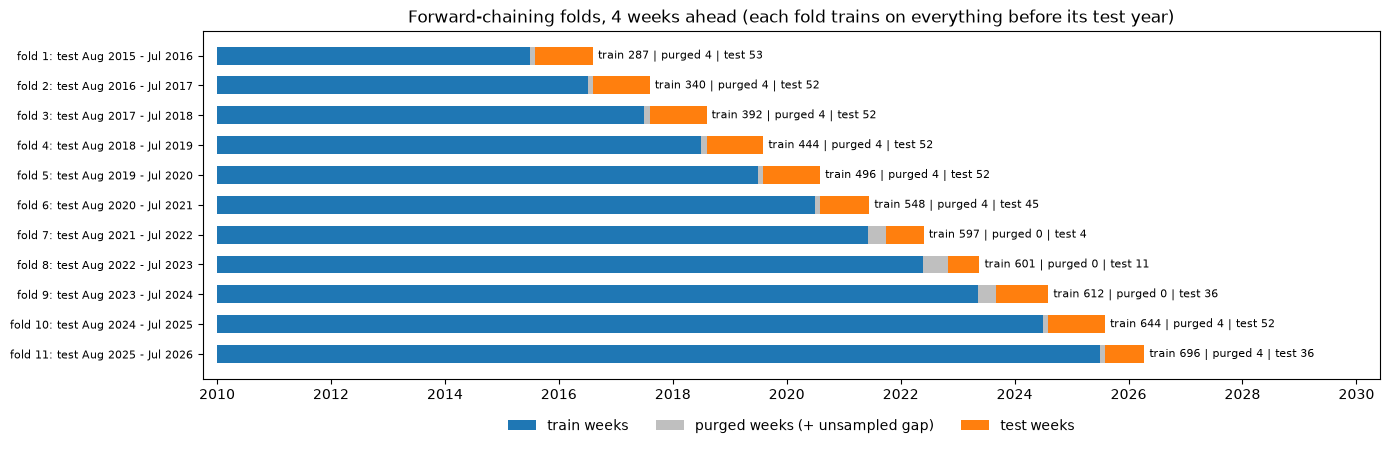

In [2]:
from common.dates import assign_bloom_year
from common.validation import make_folds, select_labelled_rows

NAMES = {0: "no bloom", 1: "at risk", 2: "bloom"}


def fold_table(h):
    """Train and test weeks of every forward-chaining fold for one horizon.

    Args:
        h (int): Weeks ahead (1, 2 or 4).

    Returns:
        pandas.DataFrame: One row per fold with date ranges, class counts and purged weeks.
    """
    t = pd.read_csv(MODELS_ROOT / "notebooks" / "outputs" / "cleaned" / "merged_weekly_sarasota.csv",
                    index_col="week_ending", parse_dates=True)
    lab = select_labelled_rows(t.assign(target=t[f"target_{h}w"], target_week=t.index + pd.Timedelta(weeks=h)))
    label_year = assign_bloom_year(pd.DatetimeIndex(lab["target_week"]))
    rows = []
    for k, (year, tr, te) in enumerate(make_folds(lab, "forward"), start=1):
        purged = ((lab["bloom_year"] < year).to_numpy() & (label_year == year))
        n_tr = lab["target"][tr].value_counts().reindex([0, 1, 2], fill_value=0)
        n_te = lab["target"][te].value_counts().reindex([0, 1, 2], fill_value=0)
        rows.append({"fold": k, "test year": f"Aug {year - 1} - Jul {year}",
                     "train from": lab.index[tr].min().date(), "train to": lab.index[tr].max().date(),
                     "train weeks": int(tr.sum()), **{f"train {NAMES[c]}": int(n_tr[c]) for c in NAMES},
                     "purged weeks": int(purged.sum()),
                     "test from": lab.index[te].min().date(), "test to": lab.index[te].max().date(),
                     "test weeks": int(te.sum()), **{f"test {NAMES[c]}": int(n_te[c]) for c in NAMES}})
    return pd.DataFrame(rows).set_index("fold")

folds_by_h = {h: fold_table(h) for h in (1, 2, 4)}

# Timeline of the folds (4 weeks ahead, where most weeks are purged): training span, purged weeks and test span per fold
f4 = folds_by_h[4]
fig, ax = plt.subplots(figsize=(14, 4.6))
for k, r in f4.iterrows():
    t0, t1 = pd.Timestamp(r["train from"]), pd.Timestamp(r["train to"])
    s0, s1 = pd.Timestamp(r["test from"]), pd.Timestamp(r["test to"])
    ax.barh(k, (t1 - t0).days, left=t0, color="tab:blue", height=0.6, label="train weeks" if k == 1 else None)
    ax.barh(k, (s0 - t1).days, left=t1, color="0.75", height=0.6, label="purged weeks (+ unsampled gap)" if k == 1 else None)
    ax.barh(k, (s1 - s0).days + 7, left=s0, color="tab:orange", height=0.6, label="test weeks" if k == 1 else None)
    ax.text(s1 + pd.Timedelta(days=40), k, f"train {r['train weeks']} | purged {r['purged weeks']} | test {r['test weeks']}",
            va="center", fontsize=8)
ax.invert_yaxis(); ax.xaxis_date()
ax.set_yticks(f4.index, [f"fold {k}: test {r['test year']}" for k, r in f4.iterrows()], fontsize=8)
ax.set_xlim(pd.Timestamp("2009-10-01"), pd.Timestamp("2030-06-01"))
ax.set_title("Forward-chaining folds, 4 weeks ahead (each fold trains on everything before its test year)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
plt.tight_layout(); plt.show()

**What the figure shows.** One row per fold, labelled with its test year; the x-axis is time. Blue = train weeks, grey = purged weeks plus any unsampled gap, orange = test weeks. The numbers at the right of each row are the same counts as the `train weeks`, `purged weeks` and `test weeks` columns in the table below. Each fold's training period ends where the previous fold's test year ends, so the training set grows by one year each time.

**The folds at each horizon.** Training and test date ranges are the weeks whose features are used; each week's label is the class *h* weeks later. `purged weeks` are training weeks removed because their label falls in the test year.

In [3]:
for h, t in folds_by_h.items():
    print(f"{h} week(s) ahead:")
    display(t)

1 week(s) ahead:


,test year,train from,train to,train weeks,train no bloom,train at risk,train bloom,purged weeks,test from,test to,test weeks,test no bloom,test at risk,test bloom
fold,,,,,,,,,,,,,,
1,Aug 2015 - Jul 2016,2010-01-03,2015-07-19,290,254,10,26,1,2015-08-02,2016-07-31,53,22,12,19
2,Aug 2016 - Jul 2017,2010-01-03,2016-07-24,343,276,22,45,1,2016-08-07,2017-07-30,52,18,6,28
3,Aug 2017 - Jul 2018,2010-01-03,2017-07-23,395,294,28,73,1,2017-08-06,2018-07-29,52,29,9,14
4,Aug 2018 - Jul 2019,2010-01-03,2018-07-22,447,324,37,86,1,2018-08-05,2019-07-28,52,29,0,23
5,Aug 2019 - Jul 2020,2010-01-03,2019-07-21,499,352,37,110,1,2019-08-04,2020-07-26,52,44,4,4
6,Aug 2020 - Jul 2021,2010-01-03,2020-07-19,551,396,41,114,1,2020-08-02,2021-06-27,48,28,11,9
7,Aug 2021 - Jul 2022,2010-01-03,2021-06-27,600,425,52,123,0,2021-10-17,2022-06-12,4,3,1,0
8,Aug 2022 - Jul 2023,2010-01-03,2022-06-12,604,428,53,123,0,2022-11-20,2023-06-04,11,5,0,6
9,Aug 2023 - Jul 2024,2010-01-03,2023-06-04,615,433,53,129,0,2023-09-24,2024-07-28,33,33,0,0


2 week(s) ahead:


,test year,train from,train to,train weeks,train no bloom,train at risk,train bloom,purged weeks,test from,test to,test weeks,test no bloom,test at risk,test bloom
fold,,,,,,,,,,,,,,
1,Aug 2015 - Jul 2016,2010-01-03,2015-07-12,289,253,10,26,2,2015-08-02,2016-07-31,53,22,12,19
2,Aug 2016 - Jul 2017,2010-01-03,2016-07-17,342,275,22,45,2,2016-08-07,2017-07-30,52,18,6,28
3,Aug 2017 - Jul 2018,2010-01-03,2017-07-16,394,293,28,73,2,2017-08-06,2018-07-29,52,28,9,15
4,Aug 2018 - Jul 2019,2010-01-03,2018-07-15,446,323,37,86,2,2018-08-05,2019-07-28,52,30,0,22
5,Aug 2019 - Jul 2020,2010-01-03,2019-07-14,498,351,37,110,2,2019-08-04,2020-07-26,52,44,4,4
6,Aug 2020 - Jul 2021,2010-01-03,2020-07-12,550,395,41,114,2,2020-08-02,2021-06-20,47,27,11,9
7,Aug 2021 - Jul 2022,2010-01-03,2021-06-20,599,424,52,123,0,2021-10-10,2022-06-05,4,3,1,0
8,Aug 2022 - Jul 2023,2010-01-03,2022-06-05,603,427,53,123,0,2022-11-13,2023-05-28,11,5,0,6
9,Aug 2023 - Jul 2024,2010-01-03,2023-05-28,614,432,53,129,0,2023-09-17,2024-07-28,34,34,0,0


4 week(s) ahead:


,test year,train from,train to,train weeks,train no bloom,train at risk,train bloom,purged weeks,test from,test to,test weeks,test no bloom,test at risk,test bloom
fold,,,,,,,,,,,,,,
1,Aug 2015 - Jul 2016,2010-01-03,2015-06-28,287,251,10,26,4,2015-08-02,2016-07-31,53,22,12,19
2,Aug 2016 - Jul 2017,2010-01-03,2016-07-03,340,273,22,45,4,2016-08-07,2017-07-30,52,18,6,28
3,Aug 2017 - Jul 2018,2010-01-03,2017-07-02,392,291,28,73,4,2017-08-06,2018-07-29,52,26,9,17
4,Aug 2018 - Jul 2019,2010-01-03,2018-07-01,444,321,37,86,4,2018-08-05,2019-07-28,52,32,0,20
5,Aug 2019 - Jul 2020,2010-01-03,2019-06-30,496,349,37,110,4,2019-08-04,2020-07-26,52,43,5,4
6,Aug 2020 - Jul 2021,2010-01-03,2020-06-28,548,393,41,114,4,2020-08-02,2021-06-06,45,26,10,9
7,Aug 2021 - Jul 2022,2010-01-03,2021-06-06,597,422,52,123,0,2021-09-26,2022-05-22,4,3,1,0
8,Aug 2022 - Jul 2023,2010-01-03,2022-05-22,601,425,53,123,0,2022-10-30,2023-05-14,11,5,0,6
9,Aug 2023 - Jul 2024,2010-01-03,2023-05-14,612,430,53,129,0,2023-09-03,2024-07-28,36,36,0,0


**Result.**

* **Training grows each fold:** at 1 week ahead from 290 weeks (fold 1) to 699 (fold 11); at 4 weeks from 287 to 696. At-risk weeks stay rare throughout.
* **Purging removes *h* weeks per fold** (1, 2 or 4): the last *h* training weeks before the test year. Folds 7–9 lose none, because sampling stopped well before those test years began, so their last training weeks are already months earlier.
* **Some test years are small:** fold 7 (Aug 2021 – Jul 2022) has 4 test weeks and fold 8 has 11, because sampling nearly stopped in 2021–2023. Their scores below are noisy.

---
## 2. Persistence

**What it is.** Next week's class = the most recently observed class. It has no parameters and uses no features except the last observed class. This is the naïve forecast, the standard benchmark every forecasting method should beat [1].

**Why it matters here.** The class rarely changes from one week to the next (94 % of no-bloom weeks stay no bloom, 84 % of bloom weeks stay bloom; `00_master_eda_and_merge.ipynb` §10.10), so persistence is hard to beat on overall accuracy. By design it can never predict a change.

**Source**
1. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), OTexts. https://otexts.com/fpp3/, §5.2 Some simple forecasting methods (naïve method).

In [4]:
model_table("persistence")

,,accuracy,macro-F1,at-risk recall,bloom recall,warning recall,warning precision,onsets flagged (of 11),escalations caught,bloom PR-AUC
horizon,feature_set,,,,,,,,,
h1w,kb_only,0.83,0.71,0.36,0.86,0.85,0.85,7,0.0,0.77
h2w,kb_only,0.79,0.65,0.28,0.80,0.80,0.80,5,0.0,0.69
h4w,kb_only,0.74,0.60,0.24,0.70,0.74,0.75,5,0.0,0.59


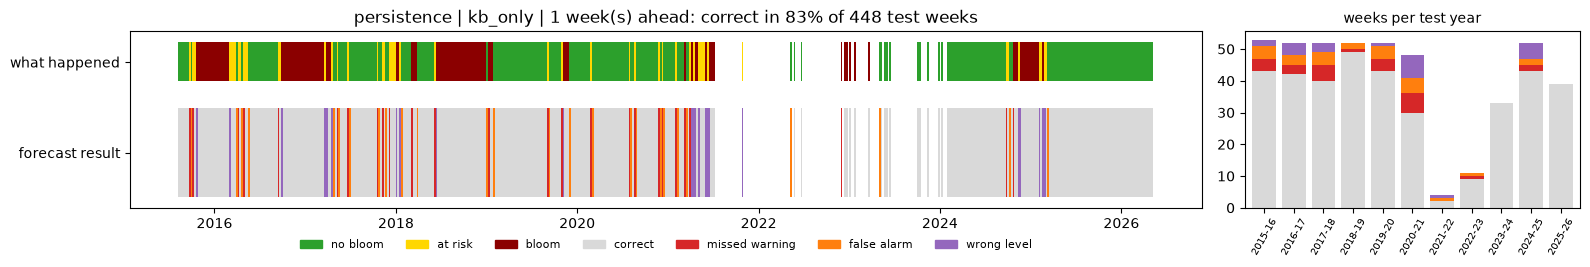

In [5]:
timeline("persistence", "kb_only")

**Score per test year** (1 week ahead, `kb_only`):

In [6]:
by_year("persistence", "kb_only")

,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
test weeks,53.00,52.00,52.00,52.00,52.00,48.00,4.00,11.00,33.00,52.00,39.00
accuracy,0.81,0.81,0.77,0.94,0.83,0.62,0.50,0.82,1.00,0.83,1.00
macro-F1,0.78,0.64,0.70,0.63,0.55,0.52,0.27,0.54,0.33,0.72,0.33


**How to read the chart.** Left: time over the test years, one block per week. The thin top strip is **what happened** (green = no bloom, yellow = at risk, dark red = bloom). The wide strip is **how the forecast did** that week:

* light grey = **correct**
* red = **missed warning**: at risk or bloom happened, but no bloom was forecast
* orange = **false alarm**: a warning was forecast, but there was no bloom
* purple = **wrong level**: at risk and bloom mixed up

Right: the same four outcomes counted per test year. Blank stretches are weeks with no sample.

For persistence, the red marks sit at the start of each yellow or dark-red stretch (it notices a change one week late), and the orange marks at the end (it keeps warning one week after a bloom ends).

**Findings**
* **The bar to beat:** macro-F1 0.71 at 1 week, 0.65 at 2 weeks and 0.60 at 4 weeks.
* **Warnings are reliable but late:** warning precision 0.75–0.85, but only 5–7 of 11 bloom onsets get a warning, and no escalation is ever caught (0 %).

---
## 3. Seasonal climatology

**What it is.** For each week of the year (± 3 weeks), the share of past weeks in each class, adjusted for how rare each class is; the forecast is the most likely class for that time of year. It uses only the date.

**Why test it.** Blooms are strongly seasonal (1 % of sampled weeks at bloom level in May, 47 % in November). This shows how much of the forecast season alone can explain.

In [7]:
model_table("seasonal_climatology")

,,accuracy,macro-F1,at-risk recall,bloom recall,warning recall,warning precision,onsets flagged (of 11),escalations caught,bloom PR-AUC
horizon,feature_set,,,,,,,,,
h1w,kb_only,0.4,0.37,0.28,0.62,0.82,0.42,9,0.77,0.42
h2w,kb_only,0.4,0.37,0.28,0.62,0.82,0.42,9,0.79,0.42
h4w,kb_only,0.4,0.37,0.28,0.62,0.82,0.42,9,0.81,0.42


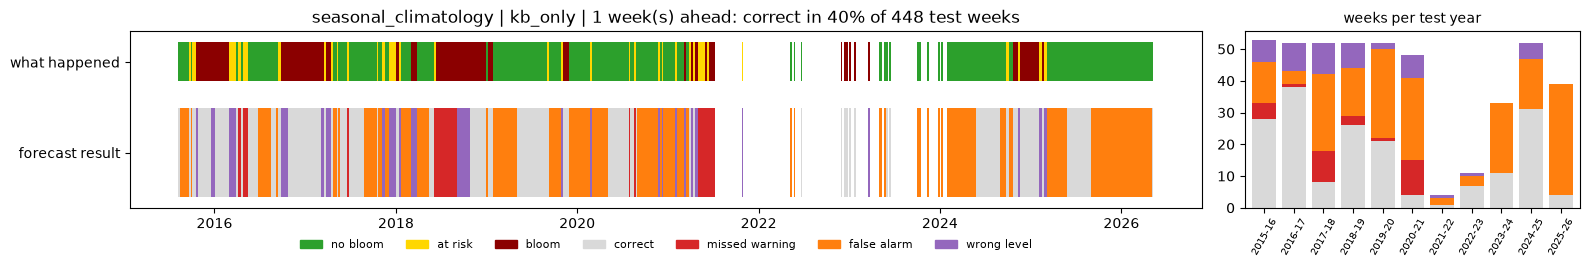

In [8]:
timeline("seasonal_climatology", "kb_only")

**Score per test year** (1 week ahead, `kb_only`):

In [9]:
by_year("seasonal_climatology", "kb_only")

,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
test weeks,53.00,52.00,52.00,52.00,52.00,48.00,4.00,11.00,33.00,52.00,39.00
accuracy,0.53,0.73,0.15,0.50,0.40,0.08,0.25,0.64,0.33,0.60,0.10
macro-F1,0.50,0.69,0.14,0.39,0.32,0.08,0.17,0.49,0.17,0.55,0.06


**Findings**
* **Weak overall:** macro-F1 0.37 at every horizon (the same season gives the same forecast whatever happened recently).
* **Many false alarms:** it warns in most autumn weeks, so warning recall is high (0.82) but warning precision is low (0.42).
* Season alone is not enough; it is used as a feature in the other models instead.

---
## 4. Logistic regression

**What it is.** A multinomial logistic regression: each class's log-odds is a weighted sum of the features. The weights can be read directly, which suits the project's aim of interpretable drivers [1].

**Set-up** (`logistic_regression/train.py`)
* Missing values filled with the training median, plus a "was missing" indicator for each feature.
* Features standardised. Both steps are fitted inside each training fold only, so test years never influence them.
* Strong L2 penalty (C = 0.1), because there are about 740 labelled weeks and up to 60 correlated features.
* Class weights balanced, so at-risk and bloom weeks count as much as no-bloom weeks.

**Source**
1. Biointerphase 1A, *Challenge Project Overview*, Suggested Approach (recommended methods include Random Forest and Gradient Boosting; success includes identifying at-risk conditions and interpretable drivers).

In [10]:
model_table("logistic_regression")

accuracy  macro-F1  at-risk recall  bloom recall  warning recall  warning precision  onsets flagged (of 11)  escalations caught  bloom PR-AUC
horizon feature_set                                                                                                                                               
h1w     kb_only          0.77      0.65            0.38          0.72            0.85               0.79                       9                0.31          0.89
        full             0.74      0.61            0.24          0.77            0.83               0.73                       7                0.31          0.87
        long             0.69      0.58            0.28          0.72            0.85               0.68                       7                0.38          0.87
        env_only         0.29      0.27            0.16          0.43            0.73               0.37                       8                0.69          0.36
h2w     kb_only          0.73      0.60            0.34          0.67            0.85               0.74                       8                0.38          0.80
        long             0.66      0.57            0.28          0.76            0.85               0.62                       9                0.47          0.82
        full             0.70      0.56            0.16          0.75            0.82               0.69                       9                0.41          0.80
        env_only         0.35      0.32            0.22          0.55            0.73               0.38                      10                0.74          0.40
h4w     kb_only          0.71      0.57            0.20          0.70            0.75               0.71                       5                0.19          0.72
        full             0.66      0.57            0.34          0.71            0.80               0.61                       6                0.51          0.75
        long             0.61      0.55            0.48          0.64            0.85               0.57                       7                0.63          0.74
        env_only         0.31      0.28            0.24          0.38            0.70               0.37                       9                0.77          0.38

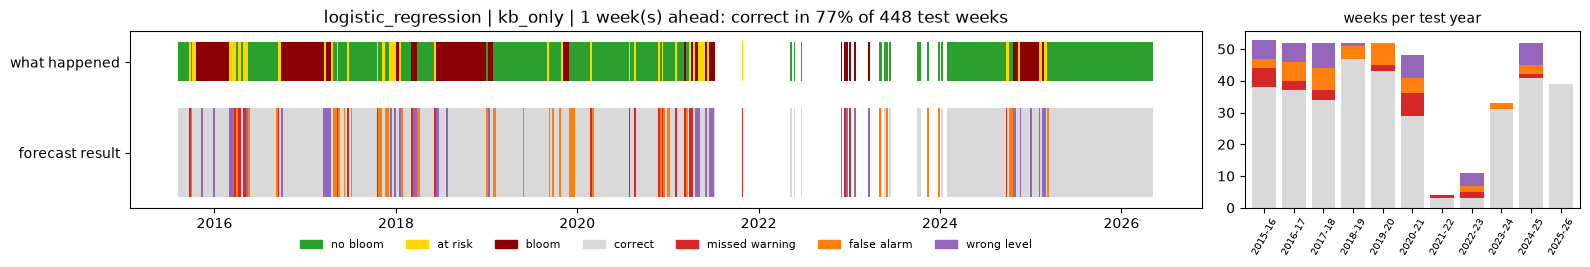

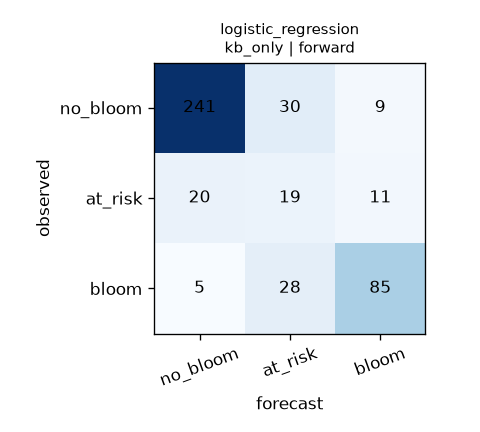

In [11]:
timeline("logistic_regression", "kb_only")
show("logistic_regression", "kb_only", kind="confusion")

**Score per test year** (1 week ahead, `kb_only`):

In [12]:
by_year("logistic_regression", "kb_only")

,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
test weeks,53.00,52.00,52.00,52.00,52.00,48.00,4.00,11.00,33.00,52.00,39.00
accuracy,0.72,0.71,0.65,0.90,0.83,0.60,0.75,0.27,0.94,0.79,1.00
macro-F1,0.62,0.61,0.59,0.62,0.69,0.45,0.29,0.20,0.32,0.70,0.33


**What the figures show.** Timeline: read as in §2 (red = missed warning, orange = false alarm, purple = wrong level). Confusion matrix: for each true class (rows), how the weeks were predicted (columns).

**Findings**
* **Best on bloom history alone (`kb_only`):** macro-F1 0.65 at 1 week, 0.61 at 2 weeks, 0.57 at 4 weeks. Below persistence at every horizon.
* **Environment alone is weak** (`env_only` macro-F1 0.27–0.32).
* **Adding the environment lowers macro-F1 at 1 week** (0.65 → 0.58 for `long`) but raises escalations caught at 4 weeks (0.19 → 0.51–0.63).
* **Good risk ranking:** bloom PR-AUC 0.89 at 1 week, against 0.77 for persistence.